# Experimental hollow-core speckle retrieval with PyTorch

Use the NF/FF camera frames from `20250716-172641`, following the preparation in
`experimental_hollow_core_speckle_retrieval_and_modal_decomp.ipynb`.
This notebook stops at field reconstruction: no modal decomposition.

Compare **AD**, **projections followed by ER**, and **projections + ER + AD**.
Choose the support, projection algorithm, and Adam or L-BFGS below. The default
projection sequence is the original **300 RAAR updates, then 200 ER updates**.
There is no known reference phase for these experimental measurements.

Run from `notebooks/` or the repository root with `speckleret` installed.

In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

root = Path.cwd()

if not (root / "speckleret").is_dir():
    root = root.parent

sys.path.insert(0, str(root))

from speckleret.plots import complex_to_hsv
from speckleret.torch import initializers, metrics, optimization, retrieval, supports, transforms


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

print("Device:", device)

Device: cuda


## Load the experimental frames

Use the same dated NF/FF pair as the source notebook. `CP` is near-field camera
intensity and `CL` is far-field camera intensity. Keep all frames for the
background estimate; choose one frame for reconstruction in the next cell.

NF: (1, 384, 384)
FF: (1, 384, 384)


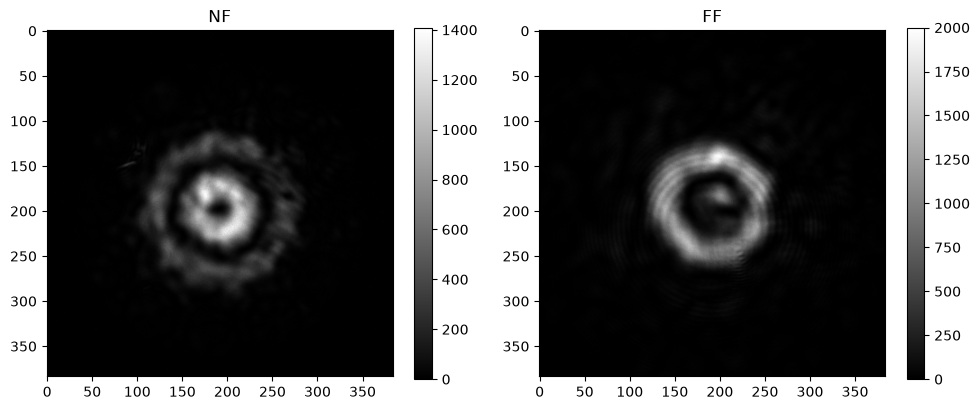

In [2]:
path = Path(r"R:\Axe-Photonique\Phocal\7531Phocal\partage\Modes and OAMs\oam")
date = "20250716-172641"

with np.load(path / f"NF__shaping_frames_{date}.npz") as data:
    CP = data["frames"].copy()

with np.load(path / f"FF__shaping_frames_{date}.npz") as data:
    CL = data["frames"].copy()

assert CP.ndim == CL.ndim == 3, "Expected [frames, height, width]."
assert len(CP) == len(CL), "NF and FF frame counts must match."
assert np.isfinite(CP).all() and np.isfinite(CL).all()

print("NF:", CP.shape)
print("FF:", CL.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, frames, title in zip(axes, (CP, CL), ("NF", "FF")):
    plot = ax.imshow(frames[0], cmap="gray", vmin=0)
    ax.set_title(title)
    fig.colorbar(plot, ax=ax)

plt.tight_layout()
plt.show()

## Preparation choices

Defaults preserve the source notebook's calibration: 561.4 nm wavelength,
100 mm focal length, 3.45 micrometer camera pixels, 4x binning in each plane,
vertical FF flip, and independent unit-energy normalization.

`legacy_abs` reproduces the original `sqrt(abs(I - background))` and averages
**amplitudes** during binning. To instead clamp negative corrected intensities,
set `background_mode = "clip"`. These choices change the prepared measurements;
keep them explicit when comparing with earlier results. Independent energy
normalization is the source notebook's relative-plane calibration assumption.

In [15]:
frame_index = 0

bin_nf = 2
bin_ff = 2

wavelength = 561.4e-9
focal_length = 100e-3
camera_pixel_size = 3.45e-6

background_mode = "legacy_abs"  # "legacy_abs" or "clip"
flip_far_vertical = True

window_size = int(
    wavelength * focal_length
    / ((bin_nf * camera_pixel_size) * (bin_ff * camera_pixel_size))
)

print("Fourier sampling window:", window_size, "x", window_size)

Fourier sampling window: 1179 x 1179


In [16]:
def estimate_background(frames, threshold):
    # Same scalar background estimator as the source notebook.
    mean_image = np.abs(frames).mean(axis=0)
    signal_mask = mean_image >= threshold * mean_image.max()
    return np.mean(np.abs(frames) * ~signal_mask[None])


background_nf = estimate_background(
    CP,
    threshold=0.05,
)

background_ff = estimate_background(
    CL,
    threshold=0.02,
)

print("Estimated NF background:", background_nf)
print("Estimated FF background:", background_ff)


def prepare_amplitude(frame, background, bin_factor):
    corrected = frame.astype(np.float32) - background

    if background_mode == "legacy_abs":
        corrected = np.abs(corrected)
    elif background_mode == "clip":
        corrected = np.maximum(corrected, 0)
    else:
        raise ValueError("Choose legacy_abs or clip.")

    amplitude = np.sqrt(corrected)
    h, w = amplitude.shape

    if h % bin_factor or w % bin_factor:
        raise ValueError("Camera dimensions must be divisible by the bin factor.")

    amplitude = amplitude.reshape(
        h // bin_factor, bin_factor, w // bin_factor, bin_factor,
    ).mean(axis=(1, 3))
    original_size = amplitude.shape

    tensor = torch.as_tensor(amplitude, dtype=torch.float32, device=device)[None, None]
    tensor = transforms.pad_to_size(tensor, (window_size, window_size))

    if not torch.any(tensor > 0):
        raise ValueError("The corrected frame has no signal.")

    tensor = transforms.normalize_field(tensor, norm_type="energy")

    return tensor, original_size


near, near_size = prepare_amplitude(CP[frame_index], background_nf, bin_nf)
far, far_size = prepare_amplitude(CL[frame_index], background_ff, bin_ff)

if flip_far_vertical:
    far = far.flip(-2)

print("Prepared NCHW shape:", tuple(near.shape))
print("Binned camera sizes:", near_size, far_size)

Estimated NF background: 8.356133355034721
Estimated FF background: 9.96282958984375
Prepared NCHW shape: (1, 1, 1179, 1179)
Binned camera sizes: (192, 192) (192, 192)


## Support choices

The support is an **object-plane** mask. `footprint` keeps the nonzero prepared
NF pixels, excluding padding. `full` reproduces the old zero-threshold support,
which includes the entire padded grid. Disk, positive intensity threshold, and
shrinkwrap are alternatives; inspect their boundaries before selecting one.
A threshold of 0.01 means 1% of peak intensity.

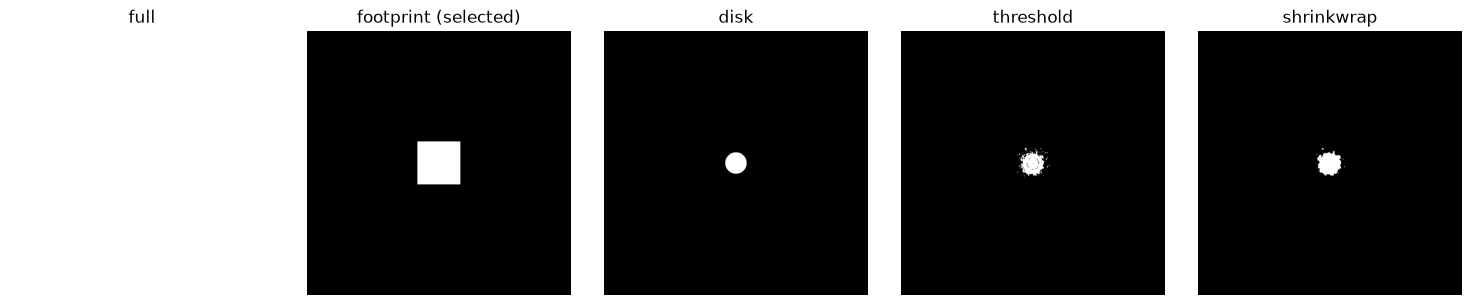

In [17]:
support_choice = "footprint"  # "full", "footprint", "disk", "threshold", "shrinkwrap"
disk_radius = 48
support_threshold = 0.01

support_options = {
    "full": torch.ones_like(near, dtype=torch.bool),
    "footprint": near > 0,
    "disk": supports.disk_support(near, radius=disk_radius),
    "threshold": supports.threshold_support(near, threshold=support_threshold),
    "shrinkwrap": supports.shrinkwrap(near, filter_sigma=2., threshold=support_threshold),
}

support = support_options[support_choice]

fig, axes = plt.subplots(1, len(support_options), figsize=(15, 3))

for ax, (name, mask) in zip(axes, support_options.items()):
    ax.imshow(mask[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(name + (" (selected)" if name == support_choice else ""))
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## Reconstruction choices

All workflows use the same random starting phase. Select RAAR, ER, HIO, OSS, or
DM; each projection run then receives the same ER finishing step. For HIO/OSS,
`enforce_magnitude=True` imposes the measured NF amplitude as well as support.
OSS manages staged outside-support smoothing automatically.

Choose Adam or L-BFGS for both AD runs. L-BFGS evaluates its closure multiple
times per outer update, so its iteration budget differs from Adam's.
Phase-only AD fixes the supported NF amplitude. The default AD objective is
normalized FF amplitude MSE; `pearson_intensity` is available if desired.
The diagnostic PCC plots below always compare **intensities**, independently
of the chosen optimization loss.

In [18]:
projection_choice = "RAAR"  # "RAAR", "ER", "HIO", "OSS", "DM"
optimizer_choice = "Adam"   # "Adam" or "L-BFGS"
loss_type = "amplitude_mse"

projection_steps = 300
er_steps = 200
ad_steps = 200 if optimizer_choice == "Adam" else 40

algorithms = {
    "RAAR": (retrieval.RAAR, {"beta": 0.9}),
    "ER": (retrieval.ER, {}),
    "HIO": (retrieval.HIO, {"beta": 0.9, "enforce_magnitude": True}),
    "OSS": (retrieval.OSS, {"beta": 0.9, "enforce_magnitude": True, "n_stages": 10}),
    "DM": (retrieval.DM, {"beta": 0.7}),
}

optimizers = {
    "Adam": (torch.optim.Adam, {"lr": 0.1}),
    "L-BFGS": (
        torch.optim.LBFGS,
        {"max_iter": 5, "history_size": 10, "line_search_fn": "strong_wolfe"},
    ),
}

algorithm, algorithm_options = algorithms[projection_choice]
optimizer, optimizer_options = optimizers[optimizer_choice]

generator = torch.Generator(device=device).manual_seed(7)
start = initializers.random_phases(near, generator=generator)
start = transforms.apply_support(start, support)

## 1. AD only

Record the same intensity PCC during AD forward evaluations. This includes
L-BFGS trial evaluations; its horizontal axis is explicitly evaluation count,
not optimizer updates. Use the last iterate so the final diagnostic corresponds
to the returned field. The same wrapper is reused for projection refinement.

In [19]:
def run_ad(initial_field):
    pcc_errors = []

    def monitored_fourier(field):
        propagated = transforms.fourier_transform(field)

        with torch.no_grad():
            error = metrics.pearson(
                propagated.abs().square(),
                far.square(),
                inversed=True,
            )
            pcc_errors.append(error.detach())

        return propagated

    field, diagnostics = optimization.reconstruct(
        (near, far),
        support=support,
        init=initial_field,
        forward_model=monitored_fourier,
        optimizer_class=optimizer,
        optimizer_kwargs=optimizer_options,
        loss_type=loss_type,
        max_iter=ad_steps,
        metric_every=10,
        return_best=False,
    )

    return field, diagnostics, torch.stack(pcc_errors)[:, 0, 0].cpu().numpy()


ad_field, ad_history, ad_pcc = run_ad(start)

## 2. Projections followed by ER

Pass the final projection state directly into ER. In particular, do not select
an earlier raw RAAR state by its Fourier residual before the ER handoff.

In [20]:
projection_state, projection_history = retrieval.run(
    (near, far),
    support=support,
    init=start,
    algorithm=algorithm,
    algorithm_kwargs=algorithm_options,
    max_iter=projection_steps,
    metric_every=10,
    return_best=False,
)

projection_field, er_history = retrieval.run(
    (near, far),
    support=support,
    init=projection_state,
    algorithm=retrieval.ER,
    max_iter=er_steps,
    metric_every=10,
    return_best=False,
)

## 3. Projections + ER + AD

Refine the exact projection result above with the selected AD optimizer.
This workflow uses both budgets. Improvement is evaluated against measured FF
intensity; no reference phase or modal basis is used.

In [21]:
hybrid_field, hybrid_history, hybrid_pcc = run_ad(projection_field)

results = {
    f"AD ({optimizer_choice})": ad_field,
    f"{projection_choice} + ER": projection_field,
    f"{projection_choice} + ER + AD": hybrid_field,
}

## Fourier field PCC: projection stages

Keep the original notebook's log-scale `1 - PCC`, blue projection stage, purple
ER stage, shaded intervals, and red 99% guide. Use the intensity history
`pearson_fourier_intens` so the values match the axis label
`1 - PCC(|y_hat|^2, |y|^2)`. The original cell used the amplitude history despite
its intensity label. Positions now use the runner's actual update numbers.
PCC measures correlation, so inspect amplitude NMSE too.

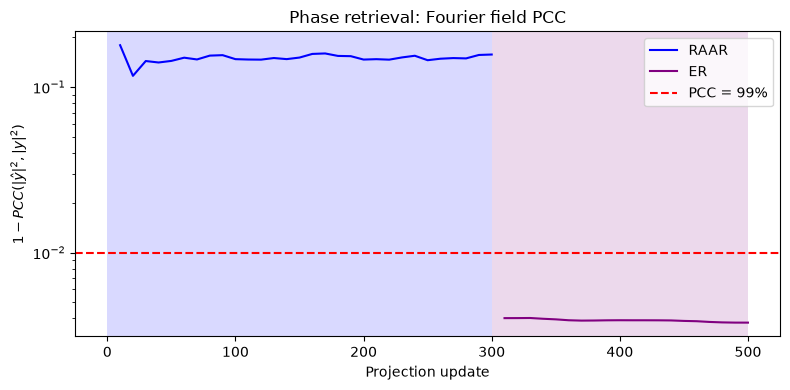

In [22]:
def style_pcc_axis(ax):
    ax.axhline(1e-2, color="red", linestyle="--", label="PCC = 99%")
    ax.set_yscale("log")
    ax.set_ylabel(r"$1 - PCC(|\hat{y}|^2, |y|^2)$")
    ax.set_title("Phase retrieval: Fourier field PCC")


fig, ax = plt.subplots(figsize=(8, 4))

for name, history, offset, color in [
    (projection_choice, projection_history, 0, "blue"),
    ("ER", er_history, projection_steps, "purple"),
]:
    steps = history["iterations"].cpu().numpy() + offset
    errors = history["pearson_fourier_intens"][:, 0, 0].cpu().numpy()

    ax.plot(steps, np.maximum(errors, 1e-8), color=color, label=name)
    ax.axvspan(offset, steps[-1], color=color, alpha=0.15, linewidth=0)

style_pcc_axis(ax)
ax.set_xlabel("Projection update")
ax.legend()

plt.tight_layout()
plt.show()

## Fourier field PCC: AD and refinement

Same intensity PCC, same vertical scale convention. Each line begins at its own
initial field: random start for AD and ER output for refinement. All AD forward
evaluations are shown, including L-BFGS trial points; temporary excursions are
not necessarily accepted optimizer updates. Exact zero errors are displayed at
`1e-8` only to allow logarithmic plotting.

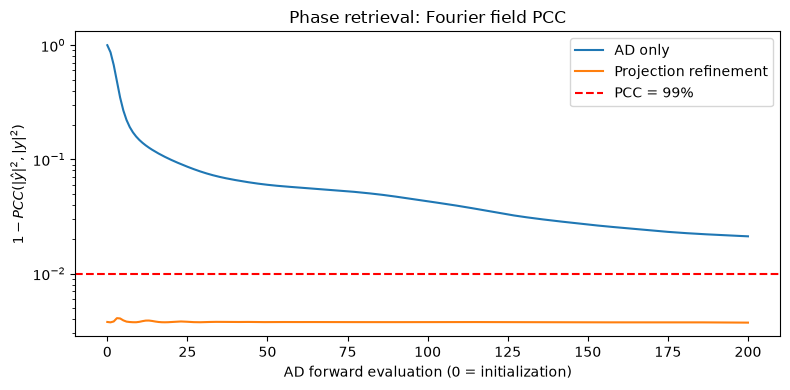

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(np.arange(len(ad_pcc)), np.maximum(ad_pcc, 1e-8), label="AD only")
ax.plot(np.arange(len(hybrid_pcc)), np.maximum(hybrid_pcc, 1e-8), label="Projection refinement")

style_pcc_axis(ax)
ax.set_xlabel("AD forward evaluation (0 = initialization)")
ax.legend()

plt.tight_layout()
plt.show()

## Amplitudes, phases, and colored fields

Each row is one reconstruction. Columns show grayscale amplitude, phase, and
HSV complex field (hue = phase, brightness = amplitude), using the same utility
as the original notebooks. Display the original **binned camera extent** rather
than the padded grid, without resizing. Choose `display_crop = False` to see
all padding. The FF crop is a display window of the padded FFT.

There is no experimental reference phase. For consistent display only, remove
each field's phase at the brightest measured NF pixel, then apply that same
offset to its FF. Each plane uses a shared amplitude scale based on its measured
amplitude, with values above that scale saturated.

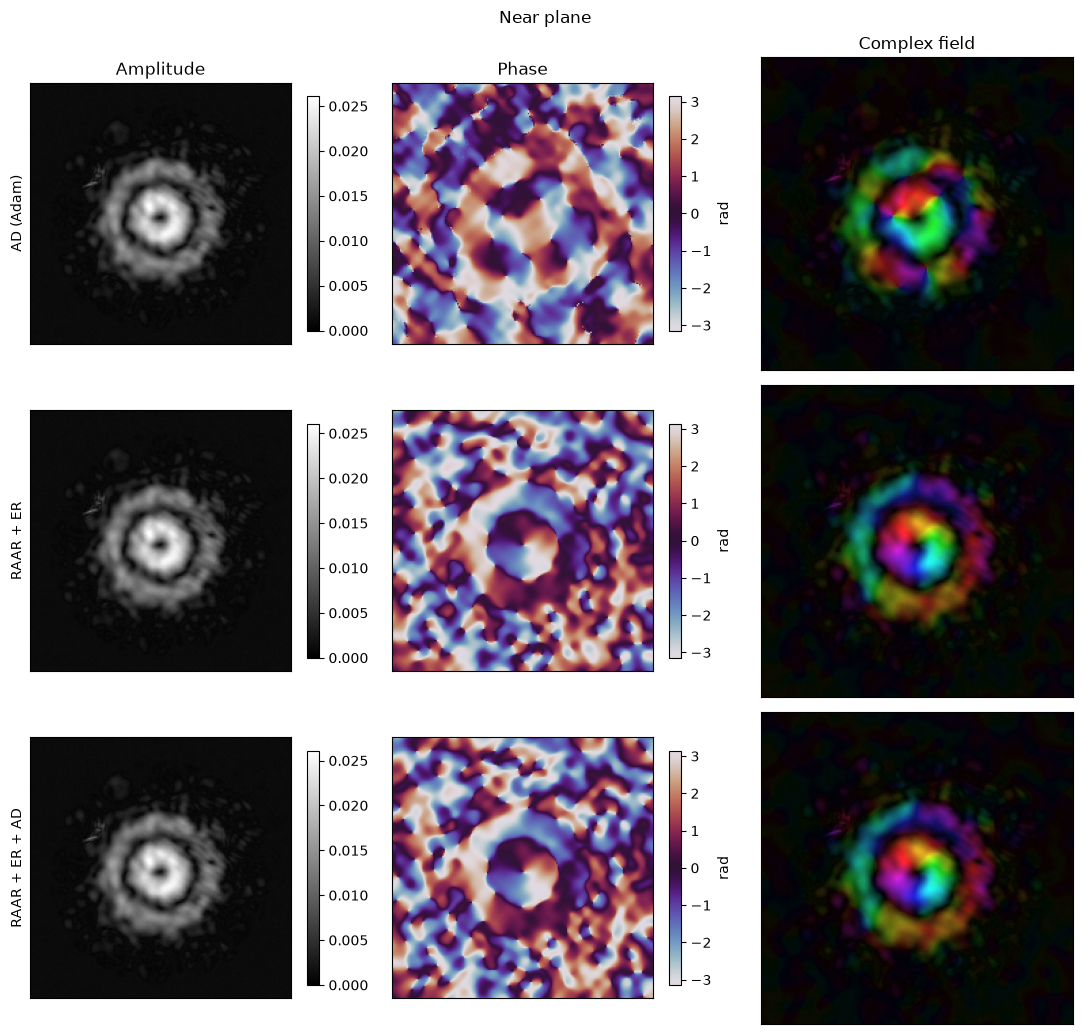

In [24]:
display_crop = True


def as_image(tensor, camera_size):
    if display_crop:
        tensor = transforms.crop_to_size(tensor, camera_size)

    return tensor.detach().cpu().numpy()[0, 0]


bright_pixel = near[0, 0].argmax().item()
row, column = divmod(bright_pixel, near.shape[-1])

aligned_fields = {}

for name, field in results.items():
    phase_offset = field[0, 0, row, column].angle()
    aligned_fields[name] = field * torch.exp(-1j * phase_offset)


def show_fields(fields, measured_amplitude, camera_size, title):
    amplitude_max = as_image(measured_amplitude, camera_size).max()
    fig, axes = plt.subplots(len(fields), 3, figsize=(11, 3.5 * len(fields)), squeeze=False)

    for axes_row, (name, field) in zip(axes, fields.items()):
        image = as_image(field, camera_size)

        amplitude_plot = axes_row[0].imshow(
            np.abs(image), cmap="gray", vmin=0, vmax=amplitude_max,
        )
        phase_plot = axes_row[1].imshow(
            np.angle(image), cmap="twilight", vmin=-np.pi, vmax=np.pi,
        )
        axes_row[2].imshow(complex_to_hsv(image, rmin=0, rmax=amplitude_max))
        axes_row[0].set_ylabel(name)

        for ax in axes_row:
            ax.set_xticks([])
            ax.set_yticks([])

        fig.colorbar(amplitude_plot, ax=axes_row[0], shrink=0.75)
        fig.colorbar(phase_plot, ax=axes_row[1], label="rad", shrink=0.75)

    for ax, label in zip(axes[0], ("Amplitude", "Phase", "Complex field")):
        ax.set_title(label)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_fields(aligned_fields, near, near_size, "Near plane")

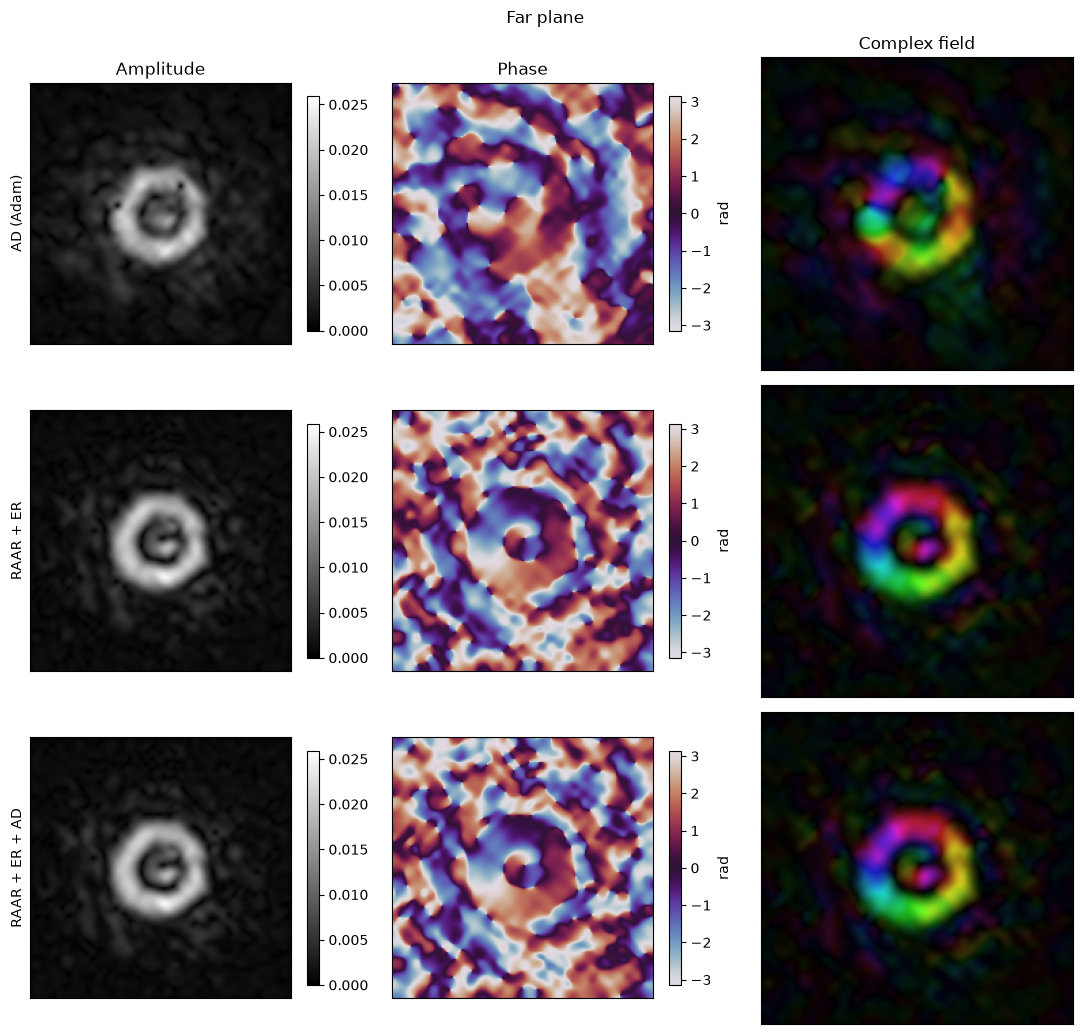

In [25]:
far_fields = {
    name: transforms.fourier_transform(field)
    for name, field in aligned_fields.items()
}

show_fields(far_fields, far, far_size, "Far plane")

## Measured versus reconstructed far amplitudes

Use the same grayscale limits for all panels. Metrics below use the full padded
grid, even when the images show only the camera window.

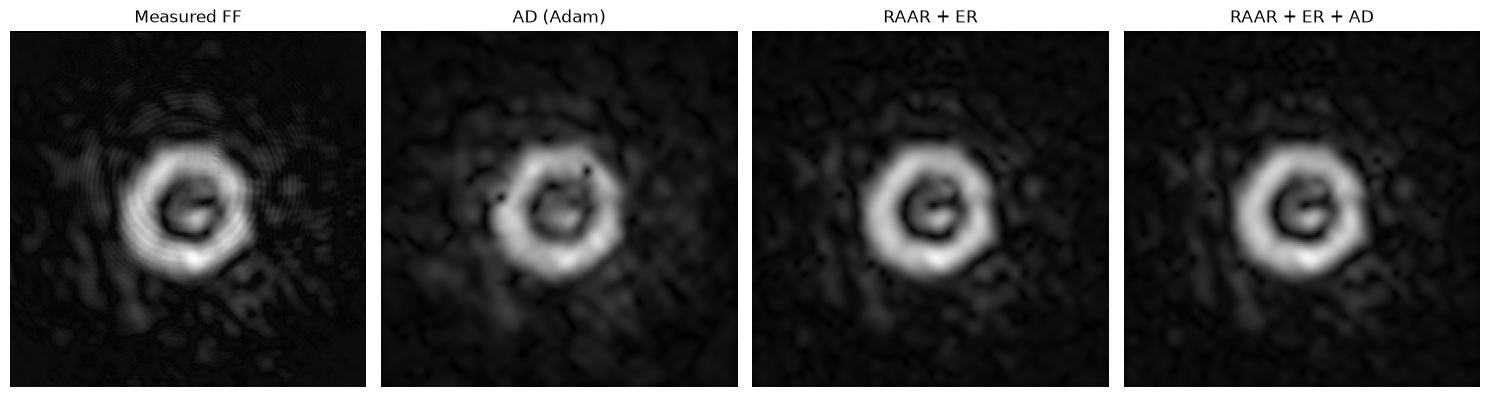

Method                         NF NMSE      FF NMSE   FF intensity PCC
AD (Adam)                    1.376e-15      0.06718           0.978800
RAAR + ER                    1.462e-15      0.02155           0.996228
RAAR + ER + AD               1.417e-15      0.02133           0.996278


In [26]:
panels = {"Measured FF": far, **far_fields}
maximum = as_image(far, far_size).max()

fig, axes = plt.subplots(1, len(panels), figsize=(15, 4))

for ax, (name, field) in zip(axes, panels.items()):
    ax.imshow(np.abs(as_image(field, far_size)), cmap="gray", vmin=0, vmax=maximum)
    ax.set_title(name)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

print(f"{'Method':<25} {'NF NMSE':>12} {'FF NMSE':>12} {'FF intensity PCC':>18}")

for name, field in results.items():
    predicted = transforms.fourier_transform(field)
    near_error = metrics.normalized_mse(field, near).item()
    far_error = metrics.normalized_mse(predicted, far).item()
    pcc = metrics.pearson(predicted.abs().square(), far.square()).item()

    print(f"{name:<25} {near_error:12.4g} {far_error:12.4g} {pcc:18.6f}")

## Further runs

Change the support or algorithm/optimizer choices and rerun the reconstruction
cells. Calibration changes (binning, flip, background policy) require rerunning
preparation too. A shifted FF pattern can appear as a phase ramp in the retrieved
NF, so agreement with camera geometry matters. Compare PCC together with NMSE;
there is no reference-field accuracy score for these experimental data.

The original source notebook and the synthetic walkthrough remain separate.